In [1]:
from google.colab import files

uploaded = files.upload()

Saving pslm_hh_subset.csv to pslm_hh_subset.csv
Saving pslm_person_subset.csv to pslm_person_subset.csv


In [2]:
import pandas as pd

person = pd.read_csv("pslm_person_subset.csv")
household = pd.read_csv("pslm_hh_subset.csv")

print("Person data shape:", person.shape)
print("Household data shape:", household.shape)

print(person.columns.tolist())
print(household.columns.tolist())

Person data shape: (107367, 47)
Household data shape: (19556, 109)
['hhid', 'idc', 'relation', 'sex', 'age', 'marital', 'born_here', 'dist_birth', 'move_year', 'dist_origin', 'mig_reason', 'diff_seeing', 'diff_hearing', 'diff_walking', 'diff_memory', 'diff_selfcare', 'diff_communicating', 'any_disability', 'can_read', 'can_write', 'can_math', 'school_type', 'grade_now', 'school_km', 'ed_admission', 'ed_uniform', 'ed_books', 'ed_exam', 'ed_tuition', 'ed_transport', 'ed_hostel', 'ed_other', 'ed_total', 'literate', 'emp_status', 'earn_month', 'months_worked', 'earn_year', 'emp_status2', 'earn_second', 'other_work', 'earn_other', 'sold_kind', 'earn_kind', 'inc_pension', 'income_shared_hh', 'earn_annual']
['hhid', 'psu', 'prov_code', 'urban_rural', 'dist_code', 'hhweight', 'hh_size', 'n_female', 'n_child', 'head_age', 'tenure', 'owner_sex', 'rooms', 'cook_fuel', 'light_fuel', 'water_source', 'water_dist_band', 'water_time_band', 'toilet_type', 'water_improved', 'toilet_flush', 'hh_inc_remit

In [3]:
# Keep only the required household columns
hh = household[["hhid", "hhweight", "prov_code", "urban_rural"]]

# Merge person and household data
data_py = person.merge(hh, on="hhid", how="inner")

# Select Sindh Urban earners aged 15–64
data_py = data_py[
    (data_py["prov_code"] == 3) &
    (data_py["urban_rural"] == 2) &
    (data_py["age"] >= 15) &
    (data_py["age"] <= 64) &
    (data_py["earn_annual"] > 0) &
    (data_py["earn_annual"].notna()) &
    (data_py["hhweight"].notna()) &
    (data_py["hhweight"] > 0)
].copy()

print("Valid earners:", len(data_py))

Valid earners: 2644


In [4]:
import numpy as np
import pandas as pd

# Create 5-year age bands
bins = list(range(15, 66, 5))
labels = [
    "15-19", "20-24", "25-29", "30-34", "35-39",
    "40-44", "45-49", "50-54", "55-59", "60-64"
]

data_py["age_band"] = pd.cut(
    data_py["age"],
    bins=bins,
    labels=labels,
    right=False
)

# Calculate weighted mean earnings
band_table = data_py.groupby(
    "age_band", observed=False
).apply(
    lambda g: pd.Series({
        "n_observations": len(g),
        "weighted_mean": np.average(
            g["earn_annual"],
            weights=g["hhweight"]
        )
    }),
    include_groups=False
).reset_index()

band_table["midpoint"] = range(17, 63, 5)

print(band_table.round(1).to_string(index=False))

age_band  n_observations  weighted_mean  midpoint
   15-19           160.0       192523.1        17
   20-24           296.0       222947.6        22
   25-29           398.0       303153.9        27
   30-34           396.0       379254.0        32
   35-39           359.0       360221.2        37
   40-44           344.0       446533.3        42
   45-49           250.0       431696.7        47
   50-54           212.0       530772.9        52
   55-59           157.0       542400.0        57
   60-64            72.0       414262.5        62


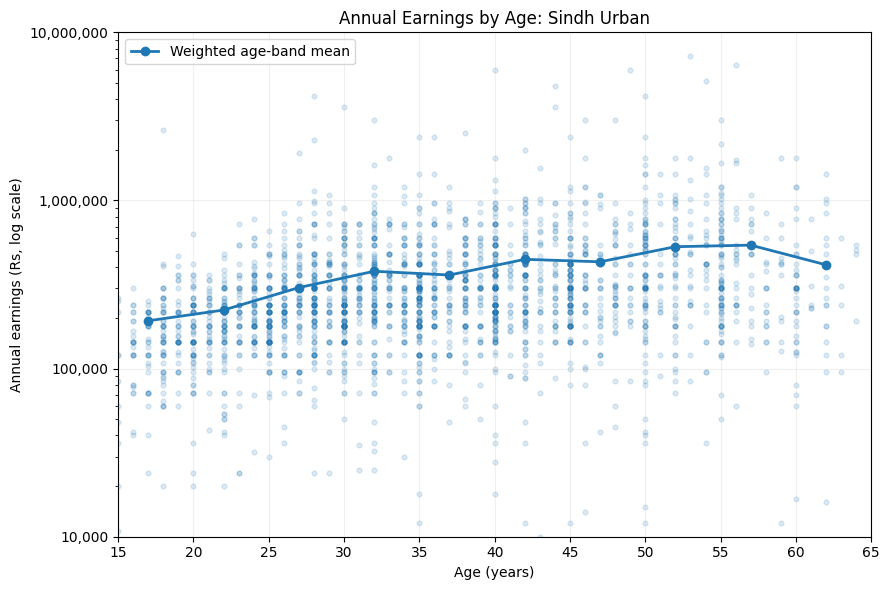

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.figure(figsize=(9, 6))

# Individual earners
plt.scatter(
    data_py["age"],
    data_py["earn_annual"],
    alpha=0.15,
    s=12
)

# Weighted age-band means
plt.plot(
    band_table["midpoint"],
    band_table["weighted_mean"],
    marker="o",
    linewidth=2,
    label="Weighted age-band mean"
)

plt.yscale("log")
plt.ylim(10000, 10000000)
plt.xlim(15, 65)
plt.xticks(range(15, 66, 5))
plt.gca().yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

plt.title("Annual Earnings by Age: Sindh Urban")
plt.xlabel("Age (years)")
plt.ylabel("Annual earnings (Rs, log scale)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig("q5_age_earnings.svg", format="svg")
plt.show()

In [6]:
from google.colab import files

files.download("q5_age_earnings.svg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>